# DDS-8555 Assignment 6: Build and Evaluate Tree Models
**Nathan Weber** · National University · DDS-8555: Predictive Analysis · Dr. Alexander Watt

**How to run:** Runtime → Run all. Approve the Google Drive prompt. The obesity data are reused from Assignment 5 (Drive → DDS8555 → obesity) and the abalone data from Assignments 2–4 (Drive → DDS8555 → abalone), so no upload should be needed. The four Kaggle submission files download automatically and are also saved to Drive → DDS8555 → output.

| Rubric item | Where |
|---|---|
| Completes Conceptual Question (ISLP Ch. 8, Q1) | Part 1 |
| Completes Applied Question (ISLP Ch. 8, Q12) | Part 2 (abalone data from Assignments 2–4) |
| Submits Decision Tree/Bagged models to Kaggle | Part 3, Models 1 and 2 |
| Submits Random Forest/Boosted models to Kaggle | Part 3, Models 3 and 4 |
| Applies regularized regression | Part 3: cost-complexity pruning (Model 1), shrinkage and L2 penalty in boosting (Model 4), and the ridge-penalized multinomial logistic baseline from A5; Part 2: OLS vs regularized ensembles |
| Investigates assumptions | Part 3, checks |
| Provides evidence of submissions | Screenshot in the paper's appendix |
| Posts code to GitHub | This notebook (repo DDS8555) |

In [1]:
# ==============================================================================
# DDS-8555 Predictive Analysis | Assignment 6 (Part 1 of 1): Build and Evaluate Tree Models
# National University | Instructor: Dr. Alexander V. Watt | Author: Nathan Weber
# Notebook: DDS8555_ASGN6Part1of1_TreeModels_NWeber.ipynb
# Paper:    WeberN_DDS8555-910002634_ASGN6Part1of1.docx  (the written report; code is not reproduced there)
# Version:  v1.0, 2026-10-20 (see the change log at the end of this cell)
# ------------------------------------------------------------------------------
# RUN:      Google Colab -> Runtime -> Run all (also runs locally with Python 3.10+).
#           Needs: numpy, pandas, matplotlib, scikit-learn, statsmodels, scipy, ISLP.
# INPUTS:   Kaggle 'Multi-Class Prediction of Obesity Risk' (playground-series-s4e2):
#           train.csv, test.csv, sample_submission.csv (or the zip) in
#           Google Drive/MyDrive/DDS8555/obesity. Textbook data come from the ISLP package.
#           https://www.kaggle.com/competitions/playground-series-s4e2
#           (synthetic data generated from the UCI obesity-levels data;
#           original: Palechor & de la Hoz Manotas, 2019, https://doi.org/10.1016/j.dib.2019.104344)
# EXTRA IN:  Q12: Kaggle abalone files (playground-series-s4e4) in Drive/MyDrive/DDS8555/abalone
#           (already there from Assignments 2-4; if missing, Q12 falls back to ISLP Carseats).
# OUTPUTS:  Drive/MyDrive/DDS8555/output: A6_model1_tree.csv, A6_model2_bagging.csv, A6_model3_random_forest.csv, A6_model4_boosting.csv, A6_fig_partition.png, A6_fig_q12.png, A6_fig_pruning.png, A6_fig_tree.png, A6_fig_importance.png, A6_fig_confusion.png, A6_results.json
# ------------------------------------------------------------------------------
# QUESTION: Four tree-based classifiers for the seven obesity classes: a pruned decision tree, bagging, a random forest, and gradient boosting, compared by 5-fold CV accuracy and Kaggle accuracy, with the A5 penalized logistic model as the baseline. Also ISLP Ch. 8 conceptual Q1 and applied Q12 (abalone).
# TARGET:   NObeyesdad (7 weight classes). Kaggle metric = accuracy (share of rows classed correctly).
# CLEANING (same in A5 and A6): no rows dropped; categorical levels one-hot encoded (levels unseen
#           in training, e.g. CALC = 'Always' in test, are ignored); numeric columns standardized
#           where a model needs it; one added feature, BMI = Weight / Height^2.
# VALIDATION: 5-fold StratifiedKFold(shuffle=True, random_state=42) on the training set only.
#           The Kaggle test set has no labels; it is scored only by Kaggle.
# SEEDS:    random_state=42 for CV folds and models; Q12 sample and split use random_state=42; BART uses random_state=0.
# DEPENDS ON: A5's load cell and BMI feature (identical); A5's penalized logistic regression is the baseline. Q12 reuses A2's abalone cleaning rule.
# CHECKS:   input SHA-256 fingerprints, row counts, column names, and package versions
#           are printed below and at the end, so a re-run can be compared line by line.
# ------------------------------------------------------------------------------
# CHANGE LOG:
#   v1.0  2026-10-20  First version.
# ==============================================================================

In [2]:
## ---- 0. Setup and imports ------------------------------------------------------
# ---- 0. Setup: runs in Google Colab (also runs locally) ----
import sys, os, glob, zipfile, json, time, warnings
warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/DDS8555"
    !pip -q install --no-deps ISLP
else:
    BASE = os.environ.get("DDS8555_BASE", ".")
DATA_DIR = os.path.join(BASE, "obesity")
OUT_DIR = os.path.join(BASE, "output")
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from ISLP import load_data
pd.set_option("display.width", 120); pd.set_option("display.max_columns", 25)
plt.rcParams["figure.dpi"] = 110
RESULTS = {}          # every number the paper uses is stored here and printed at the end
T0 = time.time()

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 17.5 MB/s eta 0:00:00


## Part 1. Conceptual Question 1 (ISLP Chapter 8)
*Question (paraphrased; ISLP p. 363):* draw an example, of your own invention, of a partition of a two-dimensional feature space that could come from recursive binary splitting, with at least six regions. Draw the matching decision tree, and label every part of both figures: the regions R1, R2, …, the cutpoints t1, t2, …, and so on.

The example below uses two predictors on 0 to 100. Splitting is **recursive** (each split acts on one region made by the earlier splits) and **binary** (each split cuts one region into two along one predictor). Five splits give six regions:

1. t1: X1 < 40 splits the space into a left part and a right part.
2. t2: in the left part, X2 < 60 separates the bottom from R3 (top left).
3. t3: in the bottom left, X1 < 20 separates R1 from R2.
4. t4: in the right part, X2 < 30 separates R4 (bottom right) from the rest.
5. t5: in the upper right, X1 < 75 separates R5 from R6.

A tree like this predicts, for any point, the mean response (regression) or the most common class (classification) of the training points in its region. Because each split is on one predictor at a time, every region is an axis-aligned rectangle; a diagonal boundary can only be approximated by a staircase of many splits.

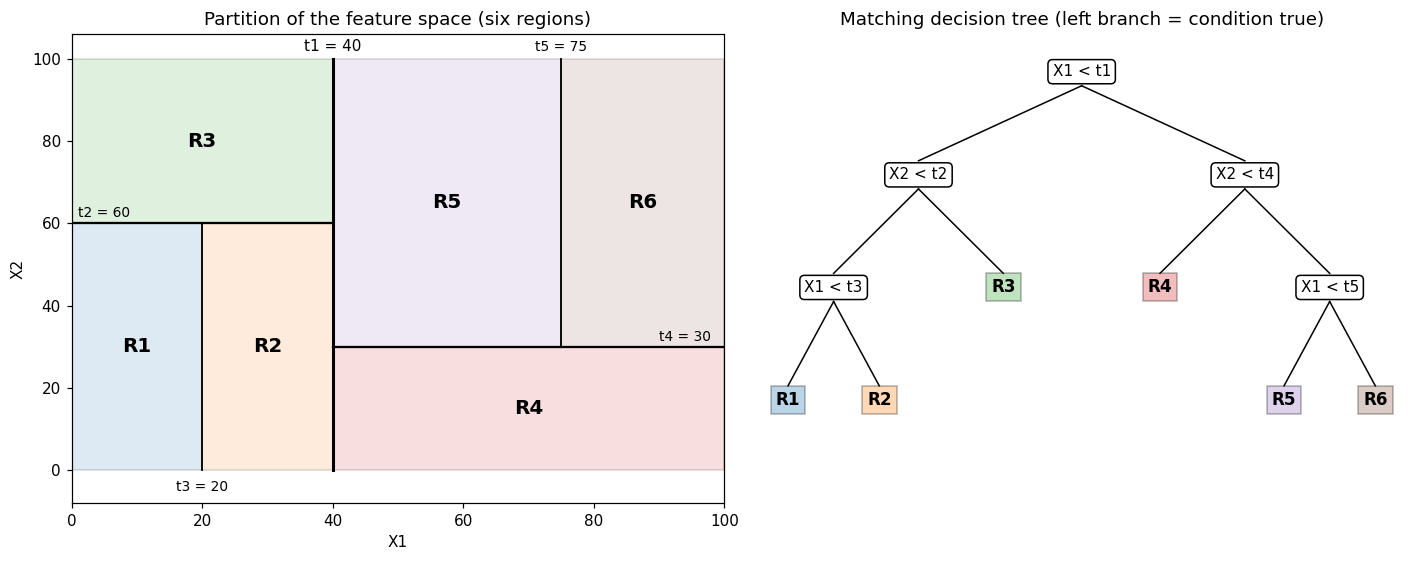

In [3]:
## ---- 1. Conceptual Q1: draw the partition and the matching tree ----------------
from matplotlib.patches import Rectangle
regions = {"R1": (0, 0, 20, 60), "R2": (20, 0, 40, 60), "R3": (0, 60, 40, 100),
           "R4": (40, 0, 100, 30), "R5": (40, 30, 75, 100), "R6": (75, 30, 100, 100)}
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
a = ax[0]
for i, (r, (x0, y0, x1, y1)) in enumerate(regions.items()):
    a.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=True, alpha=.15, color=f"C{i}", ec="k"))
    a.text((x0 + x1) / 2, (y0 + y1) / 2, r, ha="center", va="center", fontsize=13, weight="bold")
a.plot([40, 40], [0, 100], "k", lw=2); a.text(40, 102, "t1 = 40", ha="center")
a.plot([0, 40], [60, 60], "k", lw=1.5); a.text(1, 61.5, "t2 = 60", fontsize=9)
a.plot([20, 20], [0, 60], "k", lw=1.2); a.text(20, -5, "t3 = 20", ha="center", fontsize=9)
a.plot([40, 100], [30, 30], "k", lw=1.5); a.text(98, 31.5, "t4 = 30", ha="right", fontsize=9)
a.plot([75, 75], [30, 100], "k", lw=1.2); a.text(75, 102, "t5 = 75", ha="center", fontsize=9)
a.set_xlim(0, 100); a.set_ylim(-8, 106); a.set_xlabel("X1"); a.set_ylabel("X2"); a.set_title("Partition of the feature space (six regions)")
b = ax[1]; b.axis("off"); b.set_xlim(0, 100); b.set_ylim(0, 100); b.set_title("Matching decision tree (left branch = condition true)")
nodes = {"t1": (50, 92, "X1 < t1"), "t2": (25, 70, "X2 < t2"), "t4": (75, 70, "X2 < t4"), "t3": (12, 46, "X1 < t3"), "t5": (88, 46, "X1 < t5")}
leaves = {"R1": (5, 22), "R2": (19, 22), "R3": (38, 46), "R4": (62, 46), "R5": (81, 22), "R6": (95, 22)}
edges = [("t1", "t2"), ("t1", "t4"), ("t2", "t3"), ("t2", "R3"), ("t4", "R4"), ("t4", "t5"), ("t3", "R1"), ("t3", "R2"), ("t5", "R5"), ("t5", "R6")]
pos = {**{k: v[:2] for k, v in nodes.items()}, **leaves}
for p_, c_ in edges:
    b.plot([pos[p_][0], pos[c_][0]], [pos[p_][1] - 3, pos[c_][1] + 3], "k", lw=1)
for k, (x, y_, lab) in nodes.items():
    b.text(x, y_, lab, ha="center", va="center", fontsize=10, bbox=dict(boxstyle="round", fc="white", ec="k"))
for i, (k, (x, y_)) in enumerate(leaves.items()):
    b.text(x, y_, k, ha="center", va="center", fontsize=11, weight="bold", bbox=dict(boxstyle="square", fc=f"C{list(regions).index(k)}", alpha=.3))
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "A6_fig_partition.png"), dpi=150); plt.show()

## Part 2. Applied Question 12 (ISLP Chapter 8)
*Question (paraphrased; ISLP p. 366):* apply boosting, bagging, random forests, and BART to a data set of your choice. Fit the models on a training set and evaluate them on a test set. How accurate are the results compared with simple methods like linear or logistic regression? Which approach is best?

**Data set chosen: abalone (Kaggle Playground S4E4, from Assignments 2–4).** It has a numeric target (Rings), so all four methods, including BART (Bayesian additive regression trees, which in ISLP is a regression method), apply directly, and the linear-regression comparison is the A2 model itself. To keep BART's run time short, a random sample of 10,000 rows is split 75/25 into training and test sets. The A2 cleaning rule and log(1 + Rings) target are reused, and the test error is reported as RMSLE, the same metric as A2–A4. If the abalone files are not in Drive, the cell falls back to ISLP's Carseats data (Sales) and says so.

Q12 data: abalone (Kaggle S4E4 training file, 10,000-row random sample) (10000, 9)
Linear regression (OLS, A2-style)                test RMSLE 0.1594   (0.0 s)
Bagging (random forest, m = p)                   test RMSLE 0.1536   (16.1 s)
Random forest (m = 3 of 9)                       test RMSLE 0.1523   (7.0 s)
Boosting (1,000 trees, depth 3, shrinkage 0.01)  test RMSLE 0.1517   (8.6 s)
BART (200 trees, ISLP)                           test RMSLE 0.1530   (12.7 s)


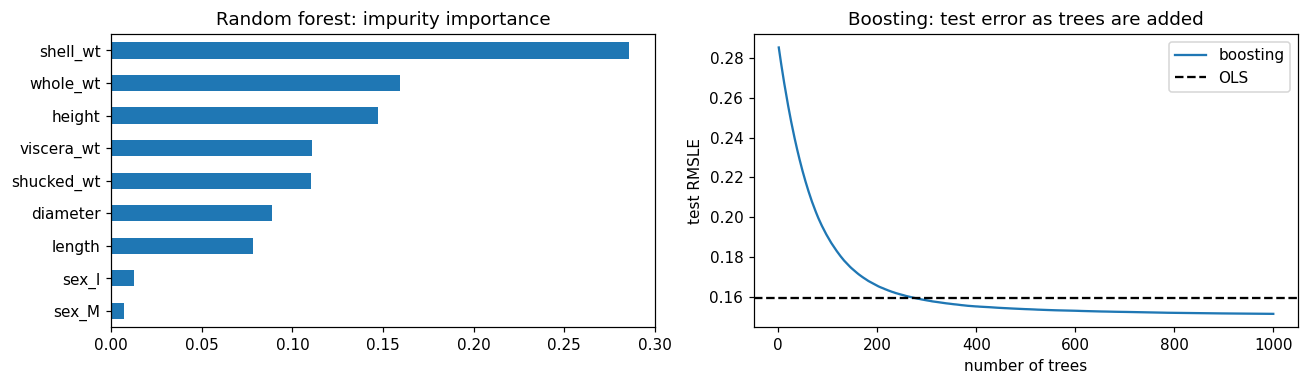

In [4]:
## ---- 2a. Applied Q12: boosting, bagging, random forest, BART vs linear regression ---
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from ISLP.bart import BART
AB_DIR = os.path.join(BASE, "abalone")
for z in glob.glob(os.path.join(AB_DIR, "*.zip")):
    zipfile.ZipFile(z).extractall(AB_DIR)
if os.path.exists(os.path.join(AB_DIR, "train.csv")):
    Q12_DATA = "abalone (Kaggle S4E4 training file, 10,000-row random sample)"
    ab = pd.read_csv(os.path.join(AB_DIR, "train.csv"))
    ab.columns = [c.strip().lower().replace(" ", "_") for c in ab.columns]
    ab = ab.rename(columns={"whole_weight": "whole_wt", "whole_weight.1": "shucked_wt", "whole_weight.2": "viscera_wt",
                            "shucked_weight": "shucked_wt", "viscera_weight": "viscera_wt", "shell_weight": "shell_wt"})
    ab = ab.sample(n=min(10000, len(ab)), random_state=42)
    med = ab.loc[ab.height > 0].groupby("sex")["height"].median()            # A2 cleaning rule
    zero = ab.height <= 0; ab.loc[zero, "height"] = ab.loc[zero, "sex"].map(med)
    num = ["length", "diameter", "height", "whole_wt", "shucked_wt", "viscera_wt", "shell_wt"]
    Xq = pd.concat([ab[num], pd.get_dummies(ab["sex"], prefix="sex", drop_first=True, dtype=float)], axis=1)
    yq = np.log1p(ab["rings"].astype(float)); METRIC = "RMSLE"
else:
    Q12_DATA = "ISLP Carseats (fallback: abalone files not found)"
    cs = load_data("Carseats")
    Xq = pd.get_dummies(cs.drop(columns="Sales"), drop_first=True, dtype=float); yq = cs["Sales"]; METRIC = "RMSE"
print("Q12 data:", Q12_DATA, Xq.shape)
Xtr, Xte, ytr, yte = train_test_split(Xq, yq, test_size=.25, random_state=42)
p_ = Xq.shape[1]
q12_models = {"Linear regression (OLS, A2-style)": LinearRegression(),
              "Bagging (random forest, m = p)": RandomForestRegressor(n_estimators=300, max_features=None, n_jobs=-1, random_state=42),
              f"Random forest (m = {max(1, p_ // 3)} of {p_})": RandomForestRegressor(n_estimators=300, max_features=max(1, p_ // 3), n_jobs=-1, random_state=42),
              "Boosting (1,000 trees, depth 3, shrinkage 0.01)": GradientBoostingRegressor(n_estimators=1000, max_depth=3, learning_rate=.01, subsample=.8, random_state=42),
              "BART (200 trees, ISLP)": BART(random_state=0, burnin=5, ndraw=15)}
q12 = {}
for name, m in q12_models.items():
    t = time.time(); m.fit(Xtr.values, ytr.values); pred = m.predict(Xte.values)
    q12[name] = {"test_error": float(np.sqrt(np.mean((pred - yte.values) ** 2))), "seconds": round(time.time() - t, 1)}
    print(f"{name:<48} test {METRIC} {q12[name]['test_error']:.4f}   ({q12[name]['seconds']} s)")
q12_tbl = pd.DataFrame(q12).T.sort_values("test_error")
ols_err = q12["Linear regression (OLS, A2-style)"]["test_error"]
# Variable importance from the random forest, and the boosting test-error curve by number of trees
rf_q = q12_models[f"Random forest (m = {max(1, p_ // 3)} of {p_})"]; gb_q = q12_models["Boosting (1,000 trees, depth 3, shrinkage 0.01)"]
stage_err = [np.sqrt(np.mean((p - yte.values) ** 2)) for p in gb_q.staged_predict(Xte.values)]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
pd.Series(rf_q.feature_importances_, index=Xq.columns).sort_values().plot.barh(ax=ax[0]); ax[0].set_title("Random forest: impurity importance")
ax[1].plot(range(1, len(stage_err) + 1), stage_err, label="boosting"); ax[1].axhline(ols_err, ls="--", c="k", label="OLS")
ax[1].set_xlabel("number of trees"); ax[1].set_ylabel(f"test {METRIC}"); ax[1].legend(); ax[1].set_title("Boosting: test error as trees are added")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "A6_fig_q12.png"), dpi=150); plt.show()
RESULTS["q12"] = {"data": Q12_DATA, "metric": METRIC, "n_train": int(len(Xtr)), "n_test": int(len(Xte)),
                  "errors": {k: v["test_error"] for k, v in q12.items()}, "best": q12_tbl.index[0], "ols": ols_err,
                  "top_importance": pd.Series(rf_q.feature_importances_, index=Xq.columns).sort_values(ascending=False).head(3).round(3).to_dict()}

In [5]:
## ---- 2b. Plain-language reading of Part 2 --------------------------------------
# ---- Plain-language reading of Part 2 (generated from the numbers above) ----
best_q = q12_tbl.index[0]; gain = 1 - q12_tbl["test_error"].iloc[0] / ols_err
print(f"* Data: {Q12_DATA}; {len(Xtr):,} training and {len(Xte):,} test rows; error = test {METRIC}.")
print("* Test error, best first: " + "; ".join(f"{k} {v:.4f}" for k, v in q12_tbl['test_error'].items()) + ".")
print(f"* Best: {best_q}, {gain:.1%} {'lower' if gain > 0 else 'higher'} error than linear regression ({ols_err:.4f}).")
worse = [k for k, v in q12.items() if v["test_error"] > ols_err]
print("* " + ("Every tree ensemble beats linear regression." if not worse else f"Not every ensemble beats linear regression: {', '.join(worse)} {'does' if len(worse) == 1 else 'do'} worse."))
print(f"* The gains are modest because the relationship is smooth and mostly monotone in the size and weight measurements; "
      f"trees help mainly by capturing curvature and interactions that OLS misses. The most important inputs: {RESULTS['q12']['top_importance']}.")

* Data: abalone (Kaggle S4E4 training file, 10,000-row random sample); 7,500 training and 2,500 test rows; error = test RMSLE.
* Test error, best first: Boosting (1,000 trees, depth 3, shrinkage 0.01) 0.1517; Random forest (m = 3 of 9) 0.1523; BART (200 trees, ISLP) 0.1530; Bagging (random forest, m = p) 0.1536; Linear regression (OLS, A2-style) 0.1594.
* Best: Boosting (1,000 trees, depth 3, shrinkage 0.01), 4.9% lower error than linear regression (0.1594).
* Every tree ensemble beats linear regression.
* The gains are modest because the relationship is smooth and mostly monotone in the size and weight measurements; trees help mainly by capturing curvature and interactions that OLS misses. The most important inputs: {'shell_wt': 0.286, 'whole_wt': 0.159, 'height': 0.147}.


## Kaggle data: Multi-Class Prediction of Obesity Risk (Playground Series S4E2)
The data load and cleaning cell is identical in Assignments 5 and 6, so both notebooks use the same data and features.
Put the Kaggle download (the zip, or `train.csv`, `test.csv`, `sample_submission.csv`) in **Google Drive → My Drive → DDS8555 → obesity**. If the files are not there, an upload button appears.

**Cleaning and features (kept the same in A5 and A6):** the competition files have no blank cells, so no rows are dropped or imputed (the cell prints the counts to confirm). The eight text columns are one-hot encoded. A level that appears only in the test file (for example CALC = "Always") gets all-zero dummies instead of an error. One feature is added: body-mass index, BMI = Weight / Height². The weight classes in the original study were defined from BMI, so BMI is the single most informative predictor; Weight and Height stay in as well.

In [6]:
## ---- 3. Load, clean, and fingerprint the Kaggle data (same as A5) --------------
# ---- Load and clean the Kaggle obesity data (same cell in A5 and A6) ----
for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
    with zipfile.ZipFile(z) as f:
        f.extractall(DATA_DIR)
NEED = ["train.csv", "test.csv", "sample_submission.csv"]
if IN_COLAB and not all(os.path.exists(os.path.join(DATA_DIR, f)) for f in NEED):
    print("Choose the Kaggle zip (or the three CSV files):")
    for name, data in files.upload().items():
        open(os.path.join(DATA_DIR, name), "wb").write(data)
    for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
        zipfile.ZipFile(z).extractall(DATA_DIR)
missing = [f for f in NEED if not os.path.exists(os.path.join(DATA_DIR, f))]
assert not missing, f"Missing files in {DATA_DIR}: {missing}"

train_raw = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_raw = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
TARGET = "NObeyesdad"
CAT = ["Gender", "family_history_with_overweight", "FAVC", "CAEC", "SMOKE", "SCC", "CALC", "MTRANS"]
NUMERIC = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE", "BMI"]
CLASSES = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
           "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]          # ordered light -> heavy
print("train:", train_raw.shape, " test:", test_raw.shape)
print("columns:", list(train_raw.columns))
EXPECTED = set(["id", TARGET] + CAT + NUMERIC[:-1])
assert EXPECTED <= set(train_raw.columns), f"Unexpected columns: {sorted(train_raw.columns)}"
assert len(test_raw) == len(sample), "test.csv and sample_submission.csv have different row counts"
assert train_raw["id"].is_unique and test_raw["id"].is_unique, "duplicate ids"
assert set(train_raw[TARGET]) <= set(CLASSES), f"unexpected classes: {set(train_raw[TARGET]) - set(CLASSES)}"

def add_features(df):
    out = df.copy()
    out["BMI"] = out["Weight"] / out["Height"] ** 2
    return out
train = add_features(train_raw); test = add_features(test_raw)
y = pd.Categorical(train[TARGET], categories=CLASSES)
y_codes = pd.Series(y.codes, index=train.index)          # 0..6 in CLASSES order

unseen = {c: sorted(set(test[c]) - set(train[c])) for c in CAT if set(test[c]) - set(train[c])}
print(f"missing values: train {int(train_raw.isna().sum().sum())}, test {int(test_raw.isna().sum().sum())}")
print(f"duplicate rows (excluding id): {int(train_raw.drop(columns='id').duplicated().sum())}")
print("levels in test but not in train (encoded as all-zero dummies):", unseen or "none")
counts = pd.Series(y).value_counts().reindex(CLASSES)
print("\nClass counts (training set):"); print(pd.DataFrame({"n": counts, "share": (counts / counts.sum()).round(3)}))
print("\nNumeric summary:"); print(train[NUMERIC].describe().T.round(3))

# ---- Provenance: fingerprint the exact input files (compare across re-runs) ----
import hashlib, datetime, platform
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()
FINGERPRINT = {f: sha256(os.path.join(DATA_DIR, f)) for f in NEED}
print("\nRun started (UTC):", datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"))
for f, hsh in FINGERPRINT.items():
    print(f"SHA-256 {f:<22} {hsh}")

# ---- Shared preprocessing and scoring helpers ----
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X = train[CAT + NUMERIC]; X_test = test[CAT + NUMERIC]

def prep(scale=True, drop="if_binary"):
    """One-hot the text columns (unseen test levels -> zeros); optionally standardize the numeric ones."""
    ohe = OneHotEncoder(handle_unknown="ignore", drop=drop, sparse_output=False)
    num = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([("cat", ohe, CAT), ("num", num, NUMERIC)], verbose_feature_names_out=False)

def cv_eval(model, name, XX=None):
    """5-fold stratified CV predictions on the training set -> accuracy, confusion matrix, seconds."""
    t = time.time()
    p = cross_val_predict(model, X if XX is None else XX, y_codes, cv=SKF, n_jobs=-1)
    acc = accuracy_score(y_codes, p)
    print(f"{name:<34} CV accuracy {acc:.4f}   ({time.time() - t:.0f} s)")
    return {"cv_acc": float(acc), "cv_pred": p, "seconds": round(time.time() - t, 1)}

def write_submission(model, name, refit=True):
    """Fit on the full training set (unless already fitted), predict the test set, save in Kaggle's format."""
    if refit:
        model.fit(X, y_codes)
    pred = np.asarray(CLASSES)[model.predict(X_test).astype(int)]
    sub = pd.DataFrame({sample.columns[0]: test["id"].values, sample.columns[1]: pred})
    path = os.path.join(OUT_DIR, name)
    sub.to_csv(path, index=False)
    print("saved", path, sub.shape, "| predicted class shares:", sub.iloc[:, 1].value_counts(normalize=True).round(3).to_dict())
    if IN_COLAB:
        files.download(path)
    return model

def per_class_recall(pred):
    cm = confusion_matrix(y_codes, pred, labels=range(len(CLASSES)))
    return {c: float(cm[i, i] / cm[i].sum()) for i, c in enumerate(CLASSES)}

def plot_confusion(pred, title, path):
    cm = confusion_matrix(y_codes, pred, labels=range(len(CLASSES)), normalize="true")
    short = ["Insuff", "Normal", "Over I", "Over II", "Obese I", "Obese II", "Obese III"]
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > .5 else "black")
    ax.set_xticks(range(7)); ax.set_xticklabels(short, rotation=45, ha="right"); ax.set_yticks(range(7)); ax.set_yticklabels(short)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title)
    plt.colorbar(im, fraction=.046); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

RESULTS["data"] = {"n_train": int(len(train)), "n_test": int(len(test)), "missing_train": int(train_raw.isna().sum().sum()),
                   "missing_test": int(test_raw.isna().sum().sum()), "unseen_levels": unseen,
                   "class_counts": {k: int(v) for k, v in counts.items()},
                   "majority_share": float(counts.max() / counts.sum()), "sha256": FINGERPRINT}

train: (20758, 18)  test: (13840, 17)
columns: ['id', 'Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS', 'NObeyesdad']
missing values: train 0, test 0
duplicate rows (excluding id): 0
levels in test but not in train (encoded as all-zero dummies): {'CALC': ['Always']}

Class counts (training set):
                        n  share
Insufficient_Weight  2523  0.122
Normal_Weight        3082  0.148
Overweight_Level_I   2427  0.117
Overweight_Level_II  2522  0.121
Obesity_Type_I       2910  0.140
Obesity_Type_II      3248  0.156
Obesity_Type_III     4046  0.195

Numeric summary:
          count    mean     std     min     25%     50%      75%      max
Age     20758.0  23.842   5.688  14.000  20.000  22.815   26.000   61.000
Height  20758.0   1.700   0.087   1.450   1.632   1.700    1.763    1.976
Weight  20758.0  87.888  26.379  39.000  66.000  84.065  111.601  165.057
FCVC    20758.0  

## Part 3. Four tree models for the seven weight classes
Trees split on raw values, so the numeric inputs are not standardized here (it would not change any split). The text columns are one-hot encoded, as in A5. Each model is scored by 5-fold stratified CV accuracy, then refit on all training rows for Kaggle.

* **Baseline: the A5 multinomial logistic regression with a ridge penalty** (regularized regression), refit here so all models share the same folds.
* **Model 1: one classification tree, pruned.** A full tree is grown, then cut back by cost-complexity pruning: a penalty α per leaf trades fit against size. α is chosen by CV (the largest α within 0.5% of the best accuracy, so the simplest good tree wins).
* **Model 2: bagging.** 300 trees, each grown on a bootstrap sample with every input available at every split (a random forest with m = p). Out-of-bag (OOB) accuracy gives a second, free error estimate.
* **Model 3: random forest.** 300 trees, but each split may use only m randomly chosen inputs, which de-correlates the trees. m is chosen by OOB accuracy.
* **Model 4: gradient boosting.** Shallow trees added one at a time, each fit to the current errors and shrunk by a learning rate. Shrinkage, an L2 penalty on leaf values, and early stopping are its regularization. The learning rate and tree size are chosen by CV.

Baseline: ridge logistic (C = 1)   CV accuracy 0.8653   (3 s)
tree: alpha -> (CV accuracy, leaves): {'0.00e+00': (0.8427, 2499), '3.42e-05': (0.8436, 2235), '4.23e-05': (0.846, 2037), '4.53e-05': (0.8464, 1826), '4.82e-05': (0.8468, 1517), '5.78e-05': (0.8529, 1327), '6.42e-05': (0.8579, 1137), '7.09e-05': (0.8595, 1015), '7.36e-05': (0.8596, 912), '8.03e-05': (0.8618, 785), '8.56e-05': (0.8632, 676), '9.34e-05': (0.8642, 554), '1.09e-04': (0.8689, 425), '1.30e-04': (0.871, 306), '1.68e-04': (0.8753, 188), '3.21e-04': (0.8763, 92), '1.47e-02': (0.8264, 9)}
Model 1: pruned tree (92 leaves)   CV accuracy 0.8763   (1 s)
Model 2: bagging (300 trees)       CV accuracy 0.8905   (115 s)
random forest OOB accuracy by m (of 26 inputs): {5: 0.9011, 8: 0.9004, 13: 0.8989}
Model 3: random forest (m = 5)     CV accuracy 0.8992   (25 s)
  boosting: learning rate 0.03, 15 leaves per tree -> CV accuracy 0.9048
  boosting: learning rate 0.03, 31 leaves per tree -> CV accuracy 0.9040
  boosting: learnin

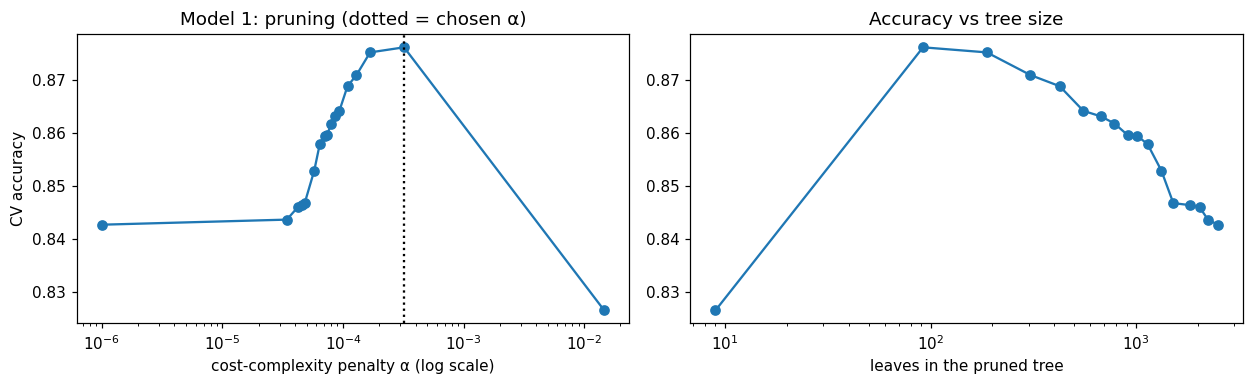

In [7]:
## ---- 4. Fit and tune the four tree models and the A5 baseline (CV accuracy) ----
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
pick_simplest = lambda sc, larger_is_simpler=True: (max if larger_is_simpler else min)(k for k, v in sc.items() if v >= max(sc.values()) * 0.995)

# ---- Baseline: ridge-penalized multinomial logistic regression (A5 Model 1, parsimony rule) ----
base_cv = {C: float(cross_val_score(make_pipeline(prep(), LogisticRegression(C=C, max_iter=4000)), X, y_codes, cv=SKF, n_jobs=-1).mean()) for C in (0.1, 1, 10, 100)}
C_base = pick_simplest(base_cv, larger_is_simpler=False)
rb = cv_eval(make_pipeline(prep(), LogisticRegression(C=C_base, max_iter=4000)), f"Baseline: ridge logistic (C = {C_base})")
FIT = {"Baseline: ridge logistic (A5)": make_pipeline(prep(), LogisticRegression(C=C_base, max_iter=4000)).fit(X, y_codes)}   # each final model is fitted once

# ---- Model 1: decision tree with cost-complexity pruning ----
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(prep(scale=False).fit_transform(X), y_codes)
alphas = np.unique(np.quantile(path.ccp_alphas[:-1], np.linspace(0, .995, 18)))
tree_cv, tree_leaves = {}, {}
for a in alphas:
    m = make_pipeline(prep(scale=False), DecisionTreeClassifier(ccp_alpha=a, random_state=42))
    tree_cv[float(a)] = float(cross_val_score(m, X, y_codes, cv=SKF, n_jobs=-1).mean())
    tree_leaves[float(a)] = int(m.fit(X, y_codes)[-1].get_n_leaves())
alpha_best = pick_simplest(tree_cv)
print("tree: alpha -> (CV accuracy, leaves):", {f"{k:.2e}": (round(v, 4), tree_leaves[k]) for k, v in tree_cv.items()})
r1 = cv_eval(make_pipeline(prep(scale=False), DecisionTreeClassifier(ccp_alpha=alpha_best, random_state=42)),
             f"Model 1: pruned tree ({tree_leaves[alpha_best]} leaves)")
FIT["1: Pruned tree"] = make_pipeline(prep(scale=False), DecisionTreeClassifier(ccp_alpha=alpha_best, random_state=42)).fit(X, y_codes)

# ---- Model 2: bagging = random forest with all inputs at every split ----
bag = make_pipeline(prep(scale=False), RandomForestClassifier(n_estimators=300, max_features=None, oob_score=True, n_jobs=-1, random_state=42))
r2 = cv_eval(bag, "Model 2: bagging (300 trees)")
FIT["2: Bagging"] = bag.fit(X, y_codes); bag_oob = float(bag[-1].oob_score_)

# ---- Model 3: random forest; m chosen by OOB accuracy ----
p_all = prep(scale=False).fit_transform(X).shape[1]
rf_oob, rf_fits = {}, {}
for m_ in sorted({int(np.sqrt(p_all)), p_all // 3, p_all // 2}):
    rf_fits[m_] = make_pipeline(prep(scale=False), RandomForestClassifier(n_estimators=300, max_features=m_, oob_score=True, n_jobs=-1,
                                                                         random_state=42)).fit(X, y_codes)
    rf_oob[m_] = float(rf_fits[m_][-1].oob_score_)
m_best = max(rf_oob, key=rf_oob.get)
FIT["3: Random forest"] = rf_fits[m_best]
print(f"random forest OOB accuracy by m (of {p_all} inputs):", {k: round(v, 4) for k, v in rf_oob.items()})
r3 = cv_eval(make_pipeline(prep(scale=False), RandomForestClassifier(n_estimators=300, max_features=m_best, n_jobs=-1, random_state=42)),
             f"Model 3: random forest (m = {m_best})")

# ---- Model 4: gradient boosting (histogram trees); shrinkage + L2 + early stopping ----
gb_cv = {}
for lr in (0.03, 0.1):
    for leaves in (15, 31):
        m = make_pipeline(prep(scale=False), HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, l2_regularization=1.0,
                          max_iter=2000, early_stopping=True, validation_fraction=.1, n_iter_no_change=50, random_state=42))
        gb_cv[(lr, leaves)] = float(cross_val_score(m, X, y_codes, cv=SKF, n_jobs=-1).mean())
        print(f"  boosting: learning rate {lr}, {leaves} leaves per tree -> CV accuracy {gb_cv[(lr, leaves)]:.4f}")
lr_best, leaves_best = max(gb_cv, key=gb_cv.get)
gbm = lambda: make_pipeline(prep(scale=False), HistGradientBoostingClassifier(learning_rate=lr_best, max_leaf_nodes=leaves_best, l2_regularization=1.0,
                            max_iter=2000, early_stopping=True, validation_fraction=.1, n_iter_no_change=50, random_state=42))
r4 = cv_eval(gbm(), f"Model 4: boosting (lr = {lr_best}, {leaves_best} leaves)")
FIT["4: Boosting"] = gbm().fit(X, y_codes)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
ax[0].semilogx([max(a, 1e-6) for a in tree_cv], list(tree_cv.values()), "o-"); ax[0].axvline(max(alpha_best, 1e-6), ls=":", c="k")
ax[0].set_xlabel("cost-complexity penalty α (log scale)"); ax[0].set_ylabel("CV accuracy"); ax[0].set_title("Model 1: pruning (dotted = chosen α)")
ax[1].plot(list(tree_leaves.values()), list(tree_cv.values()), "o-"); ax[1].set_xscale("log"); ax[1].set_xlabel("leaves in the pruned tree"); ax[1].set_title("Accuracy vs tree size")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "A6_fig_pruning.png"), dpi=150); plt.show()

### Assumption checks and diagnostics
Tree methods make almost no distributional assumptions: no normality, no linearity, no equal variances, and no need to scale the inputs. What still matters is checked below.
* **Independent rows.** The training rows should be independent draws. Duplicates and the synthetic origin of the data are noted.
* **Overfitting.** A single deep tree memorizes its data. The gap between training accuracy and CV accuracy shows how much each model overfits.
* **OOB vs CV agreement.** For bagging and random forests, out-of-bag accuracy should be close to CV accuracy. If it is, both estimates can be trusted.
* **Correlated inputs.** Height, Weight, and BMI are strongly related. Impurity-based importance spreads credit among correlated inputs and favours inputs with many split points, so permutation importance (the drop in accuracy when one input is shuffled, on held-out rows) is reported alongside it.
* **Class imbalance.** Per-class recall shows whether small classes are being sacrificed.

                               train_acc  cv_acc     gap
Baseline: ridge logistic (A5)     0.8679  0.8653  0.0026
1: Pruned tree                    0.8918  0.8763  0.0155
2: Bagging                        1.0000  0.8905  0.1095
3: Random forest                  1.0000  0.8992  0.1008
4: Boosting                       0.9472  0.9053  0.0419
Unpruned tree (for comparison)     CV accuracy 0.8427   (1 s)
OOB vs CV: bagging 0.8939 vs 0.8905; random forest 0.9011 vs 0.8992


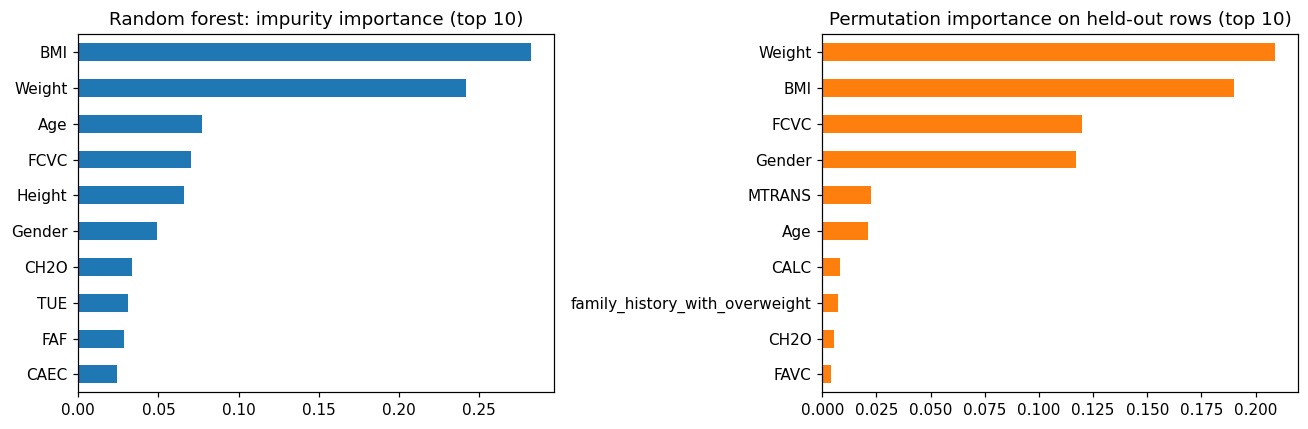

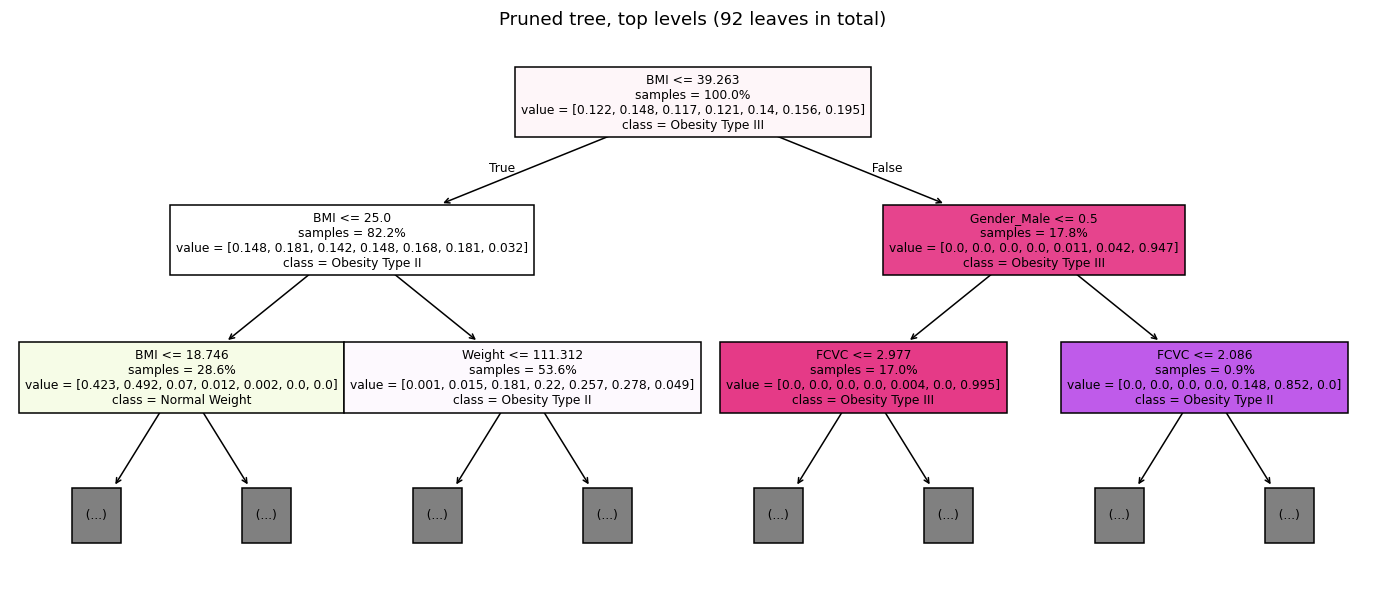

In [8]:
## ---- 5. Assumption checks and diagnostics --------------------------------------
from sklearn.inspection import permutation_importance
from sklearn.base import clone
models = {k: (r, FIT[k]) for k, r in zip(FIT, (rb, r1, r2, r3, r4))}
overfit = {}
for k, (r, m) in models.items():
    tr_acc = float(accuracy_score(y_codes, m.predict(X)))
    overfit[k] = {"train_acc": tr_acc, "cv_acc": r["cv_acc"], "gap": tr_acc - r["cv_acc"]}
print(pd.DataFrame(overfit).T.round(4))
deep = make_pipeline(prep(scale=False), DecisionTreeClassifier(random_state=42))
deep_cv = cv_eval(deep, "Unpruned tree (for comparison)")["cv_acc"]; deep_leaves = int(deep.fit(X, y_codes)[-1].get_n_leaves())
print(f"OOB vs CV: bagging {bag_oob:.4f} vs {r2['cv_acc']:.4f}; random forest {rf_oob[m_best]:.4f} vs {r3['cv_acc']:.4f}")

# Importance: impurity (from the forest) vs permutation (on one held-out fold, original columns)
rf_fit = clone(FIT["3: Random forest"])
tr_idx, ho_idx = next(SKF.split(X, y_codes))
rf_fit.fit(X.iloc[tr_idx], y_codes.iloc[tr_idx])
perm = permutation_importance(rf_fit, X.iloc[ho_idx], y_codes.iloc[ho_idx], n_repeats=5, random_state=42, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
imp = pd.Series(rf_fit[-1].feature_importances_, index=rf_fit[0].get_feature_names_out())
imp_orig = imp.groupby(lambda n: next((c for c in CAT if n.startswith(c + "_")), n)).sum().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
imp_orig.head(10)[::-1].plot.barh(ax=ax[0]); ax[0].set_title("Random forest: impurity importance (top 10)")
perm_s.head(10)[::-1].plot.barh(ax=ax[1], color="C1"); ax[1].set_title("Permutation importance on held-out rows (top 10)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "A6_fig_importance.png"), dpi=150); plt.show()

# What the pruned tree looks like (top three levels)
tree_fit = FIT["1: Pruned tree"]
plt.figure(figsize=(16, 6.5))
plot_tree(tree_fit[-1], max_depth=2, feature_names=list(tree_fit[0].get_feature_names_out()), class_names=[c.replace("_", " ") for c in CLASSES],
          filled=True, impurity=False, proportion=True, fontsize=8)
plt.title(f"Pruned tree, top levels ({tree_leaves[alpha_best]} leaves in total)"); plt.savefig(os.path.join(OUT_DIR, "A6_fig_tree.png"), dpi=150, bbox_inches="tight"); plt.show()
root = tree_fit[0].get_feature_names_out()[tree_fit[-1].tree_.feature[0]]; root_t = float(tree_fit[-1].tree_.threshold[0])
RESULTS["checks"] = {"overfit": overfit, "deep_tree_cv": deep_cv, "deep_tree_leaves": deep_leaves, "bag_oob": bag_oob, "rf_oob": rf_oob,
                     "perm_top": perm_s.head(5).round(4).to_dict(), "impurity_top": imp_orig.head(5).round(4).to_dict(),
                     "root_split": [root, root_t], "duplicates": int(train_raw.drop(columns="id").duplicated().sum())}

                               CV accuracy  seconds
4: Boosting                         0.9053     15.0
3: Random forest                    0.8992     25.2
2: Bagging                          0.8905    114.8
1: Pruned tree                      0.8763      0.9
Baseline: ridge logistic (A5)       0.8653      3.1
majority-class rate: 0.1949


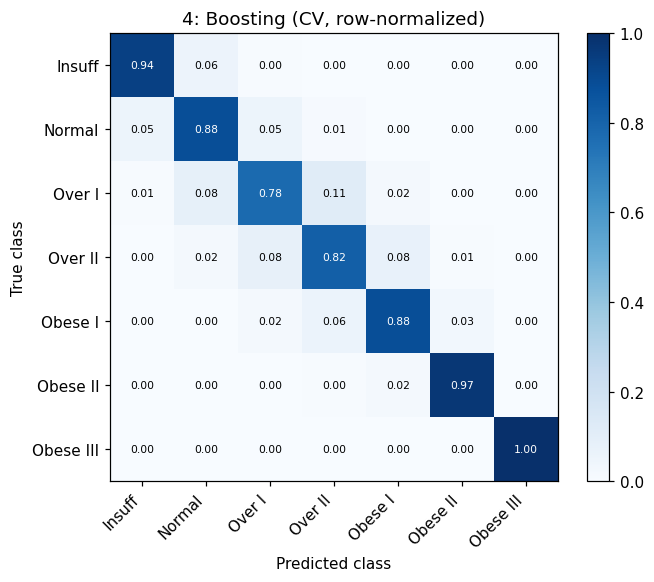

                     precision    recall  f1-score   support

Insufficient_Weight      0.927     0.935     0.931      2523
      Normal_Weight      0.874     0.884     0.879      3082
 Overweight_Level_I      0.812     0.775     0.793      2427
Overweight_Level_II      0.804     0.819     0.811      2522
     Obesity_Type_I      0.888     0.884     0.886      2910
    Obesity_Type_II      0.967     0.971     0.969      3248
   Obesity_Type_III      0.997     0.997     0.997      4046

           accuracy                          0.905     20758
          macro avg      0.895     0.895     0.895     20758
       weighted avg      0.905     0.905     0.905     20758

saved /content/drive/MyDrive/DDS8555/output/A6_model1_tree.csv (13840, 2) | predicted class shares: {'Obesity_Type_III': 0.19, 'Obesity_Type_II': 0.155, 'Normal_Weight': 0.153, 'Obesity_Type_I': 0.144, 'Overweight_Level_II': 0.136, 'Insufficient_Weight': 0.128, 'Overweight_Level_I': 0.095}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved /content/drive/MyDrive/DDS8555/output/A6_model2_bagging.csv (13840, 2) | predicted class shares: {'Obesity_Type_III': 0.189, 'Obesity_Type_II': 0.154, 'Normal_Weight': 0.15, 'Obesity_Type_I': 0.148, 'Insufficient_Weight': 0.125, 'Overweight_Level_II': 0.125, 'Overweight_Level_I': 0.108}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

saved /content/drive/MyDrive/DDS8555/output/A6_model4_boosting.csv (13840, 2) | predicted class shares: {'Obesity_Type_III': 0.19, 'Obesity_Type_II': 0.153, 'Normal_Weight': 0.153, 'Obesity_Type_I': 0.149, 'Overweight_Level_II': 0.128, 'Insufficient_Weight': 0.124, 'Overweight_Level_I': 0.103}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
## ---- 6. Compare and write the Kaggle files -------------------------------------
# ---- Compare and write the Kaggle files ----
table = pd.DataFrame({k: {"CV accuracy": r["cv_acc"], "seconds": r["seconds"]} for k, (r, m) in models.items()}).T.sort_values("CV accuracy", ascending=False)
print(table.round(4)); print(f"majority-class rate: {RESULTS['data']['majority_share']:.4f}")
best_name = table.index[0]
plot_confusion(models[best_name][0]["cv_pred"], f"{best_name} (CV, row-normalized)", os.path.join(OUT_DIR, "A6_fig_confusion.png"))
print(classification_report(y_codes, models[best_name][0]["cv_pred"], target_names=CLASSES, digits=3))
write_submission(FIT["1: Pruned tree"], "A6_model1_tree.csv", refit=False)
write_submission(FIT["2: Bagging"], "A6_model2_bagging.csv", refit=False)
write_submission(FIT["3: Random forest"], "A6_model3_random_forest.csv", refit=False)
write_submission(FIT["4: Boosting"], "A6_model4_boosting.csv", refit=False)
bp_ = models[best_name][0]["cv_pred"]; wrong = bp_ != y_codes.values

RESULTS_FILE = "A6_results.json"
RESULTS["models"] = {k: {"cv_acc": r["cv_acc"], "seconds": r["seconds"], "recall": per_class_recall(r["cv_pred"])} for k, (r, m) in models.items()}
RESULTS["tuning"] = {"base_C": base_cv, "C_base": C_base, "tree_alpha": {f"{k:.3e}": v for k, v in tree_cv.items()},
                     "tree_leaves": {f"{k:.3e}": v for k, v in tree_leaves.items()}, "alpha_best": alpha_best,
                     "leaves_best": tree_leaves[alpha_best], "rf_m": m_best, "p_inputs": p_all,
                     "gb": {f"lr={k[0]}, leaves={k[1]}": v for k, v in gb_cv.items()}, "gb_lr": lr_best, "gb_leaves": leaves_best,
                     "gb_trees_used": int(FIT["4: Boosting"][-1].n_iter_)}
RESULTS["best"] = best_name
RESULTS["adjacent_error_share"] = float((np.abs(bp_ - y_codes.values)[wrong] == 1).mean())

In [10]:
## ---- 7. Plain-language reading of Part 3 ---------------------------------------
# ---- Plain-language reading of Part 3 (generated from the numbers above) ----
acc = table["CV accuracy"]; ck = RESULTS["checks"]
print(f"* Best: {best_name} ({acc.iloc[0]:.4f}); then " + "; ".join(f"{k} {v:.4f}" for k, v in acc.iloc[1:].items()) + f". Majority-class rate {RESULTS['data']['majority_share']:.4f}.")
base = RESULTS["models"]["Baseline: ridge logistic (A5)"]["cv_acc"]
ens_beat = [k for k in ("2: Bagging", "3: Random forest", "4: Boosting") if RESULTS["models"][k]["cv_acc"] > base]
print(f"* Against the A5 penalized logistic baseline ({base:.4f}): " + (f"{', '.join(ens_beat)} beat it." if ens_beat else "no ensemble beats it.")
      + f" The single pruned tree scores {RESULTS['models']['1: Pruned tree']['cv_acc']:.4f}.")
print(f"* Pruning: the unpruned tree has {ck['deep_tree_leaves']:,} leaves and CV accuracy {ck['deep_tree_cv']:.4f}; the pruned tree keeps "
      f"{RESULTS['tuning']['leaves_best']} leaves at {RESULTS['models']['1: Pruned tree']['cv_acc']:.4f}. Its first split is {ck['root_split'][0]} < {ck['root_split'][1]:.2f}.")
print(f"* Overfitting (training minus CV accuracy): " + "; ".join(f"{k} {v['gap']:+.3f}" for k, v in ck['overfit'].items())
      + ". Bagging and forests fit their training rows almost perfectly by design, so their CV and OOB scores are the honest ones.")
print(f"* OOB vs CV: bagging {bag_oob:.4f} vs {RESULTS['models']['2: Bagging']['cv_acc']:.4f}; random forest {rf_oob[m_best]:.4f} vs {RESULTS['models']['3: Random forest']['cv_acc']:.4f}"
      f" ({'close agreement' if max(abs(bag_oob - RESULTS['models']['2: Bagging']['cv_acc']), abs(rf_oob[m_best] - RESULTS['models']['3: Random forest']['cv_acc'])) < .01 else 'a gap worth noting'}).")
print(f"* Most important inputs (permutation, held-out rows): {ck['perm_top']}. Impurity importance ranks: {list(ck['impurity_top'])}. "
      "Where the two disagree, the correlated trio Height, Weight, BMI is sharing credit.")
print(f"* Boosting chose learning rate {lr_best} with {leaves_best} leaves per tree and stopped early at {RESULTS['tuning']['gb_trees_used']} rounds. "
      f"{RESULTS['adjacent_error_share']:.0%} of the best model's errors are between neighbouring classes.")

* Best: 4: Boosting (0.9053); then 3: Random forest 0.8992; 2: Bagging 0.8905; 1: Pruned tree 0.8763; Baseline: ridge logistic (A5) 0.8653. Majority-class rate 0.1949.
* Against the A5 penalized logistic baseline (0.8653): 2: Bagging, 3: Random forest, 4: Boosting beat it. The single pruned tree scores 0.8763.
* Pruning: the unpruned tree has 2,499 leaves and CV accuracy 0.8427; the pruned tree keeps 92 leaves at 0.8763. Its first split is BMI < 39.26.
* Overfitting (training minus CV accuracy): Baseline: ridge logistic (A5) +0.003; 1: Pruned tree +0.015; 2: Bagging +0.110; 3: Random forest +0.101; 4: Boosting +0.042. Bagging and forests fit their training rows almost perfectly by design, so their CV and OOB scores are the honest ones.
* OOB vs CV: bagging 0.8939 vs 0.8905; random forest 0.9011 vs 0.8992 (close agreement).
* Most important inputs (permutation, held-out rows): {'Weight': 0.2091, 'BMI': 0.1899, 'FCVC': 0.1199, 'Gender': 0.1171, 'MTRANS': 0.0225}. Impurity importance rank

In [11]:
## ---- 8. Environment report and results JSON ------------------------------------
# ---- Environment report (the Python equivalent of R's sessionInfo()) ----
import importlib, platform
VERSIONS = {"python": platform.python_version()}
for pkg in ("numpy", "pandas", "sklearn", "statsmodels", "scipy", "matplotlib", "ISLP"):
    try:
        VERSIONS[pkg] = importlib.import_module(pkg).__version__
    except Exception:
        VERSIONS[pkg] = "not installed"
print("Environment:", VERSIONS)
print(f"Total run time: {(time.time() - T0) / 60:.1f} min")
RESULTS["environment"] = VERSIONS

# ---- Results used in the paper (printed so they are saved in the notebook) ----
def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items() if not str(k).startswith("_")}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, np.ndarray):
        return None
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o
RESULTS = _clean(RESULTS)
with open(os.path.join(OUT_DIR, RESULTS_FILE), "w") as f:
    json.dump(RESULTS, f, indent=1)
print("RESULTS_JSON_START")
print(json.dumps(RESULTS))
print("RESULTS_JSON_END")

Environment: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'statsmodels': '0.15.0', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'ISLP': '0.5.1'}
Total run time: 7.5 min
RESULTS_JSON_START
{"q12": {"data": "abalone (Kaggle S4E4 training file, 10,000-row random sample)", "metric": "RMSLE", "n_train": 7500, "n_test": 2500, "errors": {"Linear regression (OLS, A2-style)": 0.15940529220018407, "Bagging (random forest, m = p)": 0.15360688563965758, "Random forest (m = 3 of 9)": 0.15232927568964627, "Boosting (1,000 trees, depth 3, shrinkage 0.01)": 0.15166948196242655, "BART (200 trees, ISLP)": 0.15303521538581516}, "best": "Boosting (1,000 trees, depth 3, shrinkage 0.01)", "ols": 0.15940529220018407, "top_importance": {"shell_wt": 0.286, "whole_wt": 0.159, "height": 0.147}}, "data": {"n_train": 20758, "n_test": 13840, "missing_train": 0, "missing_test": 0, "unseen_levels": {"CALC": ["Always"]}, "class_counts": {"Insufficient_Weight": 2523, "Normal_Weight": 308